In [ ]:
import pandas as pd

df = pd.read_csv("../data/ground_truth.csv")
print(df.shape)  # expect (16, 12)
print(df[["diplotype", "indication", "strength"]])

assert df[["gene", "diplotype", "phenotype", "recommendation", "strength"]].isna().sum().sum() == 0
assert set(df["strength"]) <= {"Strong", "Moderate", "No recommendation"}
print("OK")

(22, 12)
   diplotype                      indication           strength
0      *1/*1                         ACS/PCI             Strong
1     *1/*17                         ACS/PCI             Strong
2    *17/*17                         ACS/PCI             Strong
3      *1/*2                         ACS/PCI             Strong
4     *2/*17                         ACS/PCI             Strong
5      *2/*2                         ACS/PCI             Strong
6    *17/*17  non-ACS non-PCI cardiovascular  No recommendation
7     *1/*17  non-ACS non-PCI cardiovascular  No recommendation
8      *1/*1  non-ACS non-PCI cardiovascular             Strong
9      *1/*2  non-ACS non-PCI cardiovascular  No recommendation
10     *2/*2  non-ACS non-PCI cardiovascular           Moderate
11   *17/*17                   neurovascular  No recommendation
12    *1/*17                   neurovascular  No recommendation
13     *1/*1                   neurovascular             Strong
14     *1/*2                   

In [ ]:
import sys
sys.path.append("../src")
from lookup import lookup

print(lookup("CYP2C19", "*17/*2", "clopidogrel", "ACS/PCI"))
print(lookup("CYP2C19", "*1/*9", "clopidogrel", "ACS/PCI"))

{'gene': 'CYP2C19', 'diplotype': '*2/*17', 'phenotype': 'Intermediate metabolizer', 'drug': 'clopidogrel', 'indication': 'ACS/PCI', 'table_ref': 'Table 2', 'recommendation': 'Avoid standard dose (75 mg) clopidogrel if possible. Use prasugrel or ticagrelor at standard dose if no contraindication.', 'strength': 'Strong', 'notes': 'Trap case: one no-function plus one increased-function allele is still IM', 'guideline_version': 'CPIC 2022 update (doi 10.1002/cpt.2526)', 'accessed_date': '2026-10-12', 'url': 'https://pmc.ncbi.nlm.nih.gov/articles/PMC9287492/', 'diplotype_norm': '*2/*17'}
{'gene': 'CYP2C19', 'diplotype': '*1/*9', 'phenotype': 'Likely intermediate metabolizer', 'drug': 'clopidogrel', 'indication': 'ACS/PCI', 'table_ref': 'Table 2', 'recommendation': 'Avoid standard dose (75 mg) clopidogrel if possible. Use prasugrel or ticagrelor at standard dose if no contraindication.', 'strength': 'Strong', 'notes': 'Likely phenotype: same strength as the confirmed phenotype (Table 2 footn

In [ ]:
import sys
sys.path.append("../src")
import pandas as pd
from lookup import lookup, _df

cases = []

# 1) One case for every row in the ground truth table
for _, r in _df.iterrows():
    if isinstance(r["notes"], str) and "Trap" in r["notes"]:
        cat = "trap"
    elif r["strength"] == "No recommendation":
        cat = "no_recommendation"
    else:
        cat = "standard"
    cases.append(dict(gene=r["gene"], diplotype=r["diplotype"],
                      drug=r["drug"], indication=r["indication"], category=cat))

# 2) Same genotypes, alleles written in the opposite order
for dip in ["*17/*2", "*17/*1", "*3/*2", "*9/*1", "*17/*3"]:
    cases.append(dict(gene="CYP2C19", diplotype=dip, drug="clopidogrel",
                      indication="ACS/PCI", category="order_swapped"))

# 3) Cases the table does not cover (the agent should say so)
cases += [
    dict(gene="CYP2C19", diplotype="*1/*12", drug="clopidogrel",
         indication="ACS/PCI", category="out_of_scope"),
    dict(gene="CYP2C19", diplotype="*1/*2", drug="prasugrel",
         indication="ACS/PCI", category="out_of_scope"),
    dict(gene="CYP2C19", diplotype="*2/*2", drug="clopidogrel",
         indication="atrial fibrillation", category="out_of_scope"),
]

# Fill in the correct answers from the lookup function
for c in cases:
    hit = lookup(c["gene"], c["diplotype"], c["drug"], c["indication"])
    c["expected_phenotype"] = hit["phenotype"] if hit else "NOT COVERED"
    c["expected_strength"] = hit["strength"] if hit else "NOT COVERED"
    c["expected_recommendation"] = hit["recommendation"] if hit else "NOT COVERED"

df_cases = pd.DataFrame(cases)
df_cases.insert(0, "case_id", [f"C{i+1:02d}" for i in range(len(df_cases))])
df_cases.to_csv("../data/cases.csv", index=False)

print(df_cases.shape)
print(df_cases["category"].value_counts())

(30, 9)
category
standard             15
no_recommendation     5
order_swapped         5
out_of_scope          3
trap                  2
Name: count, dtype: int64


In [ ]:
import pandas as pd
print(pd.read_csv("../data/ground_truth.csv").shape)

(22, 12)


In [ ]:
%pip install google-genai python-dotenv

In [ ]:
from dotenv import load_dotenv
import os

load_dotenv("../.env")
print(bool(os.getenv("GEMINI_API_KEY")))

True


In [ ]:
from dotenv import load_dotenv
load_dotenv("../.env")
from google import genai

client = genai.Client()
for m in client.models.list():
    if "gemini" in m.name or "gemma" in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-pro
models/gemini-2.5-flash-preview-tts
models/gemini-2.5-pro-preview-tts
models/gemma-4-26b-a4b-it
models/gemma-4-31b-it
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-pro-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-pro-preview
models/gemini-3.1-pro-preview-customtools
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3-pro-image-preview
models/gemini-3-pro-image
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-nano-banana-2.1
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.5-transcribe
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-4-argon
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-t

In [ ]:
import sys
sys.path.append("../src")
from llm import call_llm

print(call_llm("Reply with exactly one word: hello", model="gemini-3.5-flash"))

hello


In [ ]:
import sys
sys.path.append("../src")
import pandas as pd
from evaluate import action_of

cases = pd.read_csv("../data/cases.csv")
print(cases["expected_recommendation"].map(action_of).value_counts())

expected_recommendation
avoid_clopidogrel       15
standard_dose            6
no_recommendation        5
not_covered              3
consider_alternative     1
Name: count, dtype: int64


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from llm import call_llm
from evaluate import prompt_alone, parse_json, score_row

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")

rows, failed = [], []
for _, c in cases.iterrows():
    try:
        text = call_llm(prompt_alone(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    except Exception as e:
        failed.append(c["case_id"])
        print("FAILED", c["case_id"], str(e)[:60])
        if len(failed) >= 3:
            break
        continue
    ans = parse_json(text)
    s = score_row(c, ans)
    s.update(case_id=c["case_id"], category=c["category"],
             model_action=(ans or {}).get("action"),
             expected_action=c["expected_recommendation"][:40])
    rows.append(s)
    time.sleep(2)

if failed:
    print("Cases not answered yet:", failed)
    print("Wait a few minutes, then run this cell again.")
else:
    res = pd.DataFrame(rows)
    res.to_csv("../data/results_llm_alone.csv", index=False)
    print(res[["parsed", "phenotype_ok", "action_ok", "strength_ok", "dangerous", "overreach"]].mean())
    print(res[["dangerous", "overreach"]].sum())
    print(res.groupby("category")["action_ok"].mean())

Model busy, waiting 20s, then retrying...
Model busy, waiting 40s, then retrying...
Model busy, waiting 60s, then retrying...
Model busy, waiting 80s, then retrying...
Model busy, waiting 100s, then retrying...
FAILED C22 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
Model busy, waiting 20s, then retrying...
Model busy, waiting 40s, then retrying...
Model busy, waiting 60s, then retrying...
Model busy, waiting 80s, then retrying...
Model busy, waiting 100s, then retrying...
FAILED C23 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
Model busy, waiting 20s, then retrying...
Model busy, waiting 40s, then retrying...
Model busy, waiting 60s, then retrying...
Model busy, waiting 80s, then retrying...
Model busy, waiting 100s, then retrying...
FAILED C24 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': '
Cases not answered yet: ['C22', 'C23', 'C24']
Wait a few minutes, then run this cell again.


In [ ]:
from dotenv import load_dotenv
load_dotenv("../.env")
from google import genai

client = genai.Client()
try:
    client.models.generate_content(model="gemini-3-flash-preview", contents="hello")
    print("OK, the model answers again")
except Exception as e:
    print(str(e)[:1500])

429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 20, model: gemini-3-flash\nPlease retry in 52m50.017061093s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@type': 'type.googleapis.com/google.rpc.QuotaFailure', 'violations': [{'quotaMetric': 'generativelanguage.googleapis.com/generate_content_free_tier_requests', 'quotaId': 'GenerateRequestsPerDayPerProjectPerModel-FreeTier', 'quotaDimensions': {'model': 'gemini-3-flash', 'location': 'global'}, 'quotaValue':

In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from llm import call_llm
from evaluate import prompt_alone, parse_json, score_row

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")

rows, failed = [], []
for _, c in cases.iterrows():
    try:
        text = call_llm(prompt_alone(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    except Exception as e:
        failed.append(c["case_id"])
        print("FAILED", c["case_id"], str(e)[:60])
        if len(failed) >= 3:
            break
        continue
    ans = parse_json(text)
    s = score_row(c, ans)
    s.update(case_id=c["case_id"], category=c["category"],
             model_action=(ans or {}).get("action"),
             expected_action=c["expected_recommendation"][:40])
    rows.append(s)
    time.sleep(2)

if failed:
    print("Cases not answered yet:", failed)
    print("Wait a few minutes, then run this cell again.")
else:
    res = pd.DataFrame(rows)
    res.to_csv("../data/results_llm_alone.csv", index=False)
    print(res[["parsed", "phenotype_ok", "action_ok", "strength_ok", "dangerous", "overreach"]].mean())
    print(res[["dangerous", "overreach"]].sum())
    print(res.groupby("category")["action_ok"].mean())

parsed          1.000000
phenotype_ok    0.888889
action_ok       0.733333
strength_ok     0.800000
dangerous       0.033333
overreach       0.166667
dtype: float64
dangerous    1.0
overreach    5.0
dtype: float64
category
no_recommendation    0.200000
order_swapped        0.800000
out_of_scope         0.666667
standard             0.866667
trap                 1.000000
Name: action_ok, dtype: float64


In [ ]:
import sys
sys.path.append("../src")
import pandas as pd
from llm import call_llm
from evaluate import prompt_alone

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")
res = pd.read_csv("../data/results_llm_alone.csv")
m = res.merge(cases[["case_id", "diplotype", "indication"]], on="case_id")
wrong = m[(m["action_ok"] == 0) | (m["dangerous"] == 1)]

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 45)
print(wrong[["case_id", "category", "diplotype", "indication", "model_action", "expected_action", "dangerous"]])

for cid in wrong["case_id"]:
    c = cases[cases["case_id"] == cid].iloc[0]
    print(cid, call_llm(prompt_alone(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL))

   case_id           category diplotype                      indication       model_action                           expected_action  dangerous
6      C07  no_recommendation   *17/*17  non-ACS non-PCI cardiovascular      standard_dose                         No recommendation        0.0
7      C08  no_recommendation    *1/*17  non-ACS non-PCI cardiovascular      standard_dose                         No recommendation        0.0
10     C11           standard     *2/*2  non-ACS non-PCI cardiovascular  no_recommendation  Avoid clopidogrel if possible. Use prasu        0.0
11     C12  no_recommendation   *17/*17                   neurovascular      standard_dose                         No recommendation        0.0
12     C13  no_recommendation    *1/*17                   neurovascular      standard_dose                         No recommendation        0.0
14     C15           standard     *1/*2                   neurovascular  avoid_clopidogrel  Consider an alternative P2Y12 inhibitor     

In [ ]:
import sys
sys.path.append("../src")
from guideline import build_guideline_text
print(build_guideline_text())

GUIDELINE EXCERPT: CPIC 2022 update, CYP2C19 genotype and clopidogrel therapy

Allele function: *1 = normal function; *2 and *3 = no function; *9 = decreased function; *17 = increased function. Any other allele (for example *12) has uncertain function.

How a diplotype becomes a phenotype:
- two normal-function alleles: Normal metabolizer
- one normal-function + one increased-function allele: Rapid metabolizer
- two increased-function alleles: Ultrarapid metabolizer
- one normal-function + one no-function allele, OR one increased-function + one no-function allele: Intermediate metabolizer
- two no-function alleles: Poor metabolizer
- one normal + one decreased, OR one increased + one decreased, OR two decreased: Likely intermediate metabolizer
- one decreased + one no-function allele: Likely poor metabolizer
- one or two uncertain-function alleles: Indeterminate (the recommendation tables below contain no recommendation for it)

A "Likely" phenotype gets the same recommendation and str

In [ ]:
import sys
sys.path.append("../src")
from guideline import build_guideline_text

text = build_guideline_text()
open("../data/guideline_excerpt.txt", "w", encoding="utf-8").write(text)

for line in text.splitlines():
    if line.startswith("Indication:"):
        print(line)
recs = [l for l in text.splitlines() if "(strength:" in l]
print("recommendation lines:", len(recs))

Indication: ACS/PCI
Indication: non-ACS non-PCI cardiovascular
Indication: neurovascular
recommendation lines: 15


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from llm import call_llm
from evaluate import parse_json, score_row
from guideline import prompt_guideline

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")

rows, failed = [], []
for _, c in cases.iterrows():
    try:
        text = call_llm(prompt_guideline(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    except Exception as e:
        failed.append(c["case_id"])
        print("FAILED", c["case_id"], str(e)[:60])
        if len(failed) >= 3:
            break
        continue
    ans = parse_json(text)
    s = score_row(c, ans)
    s.update(case_id=c["case_id"], category=c["category"],
             model_action=(ans or {}).get("action"),
             expected_action=c["expected_recommendation"][:40])
    rows.append(s)
    time.sleep(2)

if failed:
    print("Cases not answered yet:", failed)
    print("Wait a few minutes, then run this cell again.")
else:
    res2 = pd.DataFrame(rows)
    res2.to_csv("../data/results_guideline.csv", index=False)
    base = pd.read_csv("../data/results_llm_alone.csv")
    cols = ["parsed", "phenotype_ok", "action_ok", "strength_ok"]
    print(pd.DataFrame({"LLM alone": base[cols].mean(),
                        "LLM + guideline": res2[cols].mean()}).round(2))
    print(pd.DataFrame({"LLM alone": base[["dangerous", "overreach"]].sum(),
                        "LLM + guideline": res2[["dangerous", "overreach"]].sum()}))
    print(res2.groupby("category")["action_ok"].mean())

              LLM alone  LLM + guideline
parsed             1.00             1.00
phenotype_ok       0.89             1.00
action_ok          0.73             0.97
strength_ok        0.80             0.97
           LLM alone  LLM + guideline
dangerous        1.0              0.0
overreach        5.0              1.0
category
no_recommendation    1.000000
order_swapped        1.000000
out_of_scope         0.666667
standard             1.000000
trap                 1.000000
Name: action_ok, dtype: float64


In [ ]:
import sys
sys.path.append("../src")
import pandas as pd
from llm import call_llm
from guideline import prompt_guideline

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")
res2 = pd.read_csv("../data/results_guideline.csv")
m = res2.merge(cases[["case_id", "diplotype", "drug", "indication"]], on="case_id")
wrong = m[(m["action_ok"] == 0) | (m["strength_ok"] == 0) | (m["phenotype_ok"] == 0)]

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 40)
print(wrong[["case_id", "category", "diplotype", "drug", "indication",
             "model_action", "expected_action", "overreach"]])
for cid in wrong["case_id"]:
    c = cases[cases["case_id"] == cid].iloc[0]
    t = call_llm(prompt_guideline(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    print(cid, " ".join(t.split()))

   case_id      category diplotype         drug           indication       model_action expected_action  overreach
29     C30  out_of_scope     *2/*2  clopidogrel  atrial fibrillation  avoid_clopidogrel     NOT COVERED        1.0
C30 { "phenotype": "Poor metabolizer", "action": "avoid_clopidogrel", "strength": "Moderate" }


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from tool_agent import call_with_tool, prompt_tool
from evaluate import parse_json, score_row

MODEL = "gemini-3-flash-preview"
N = 30          
cases = pd.read_csv("../data/cases.csv").head(N)

rows, failed = [], []
for _, c in cases.iterrows():
    try:
        text, calls = call_with_tool(prompt_tool(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    except Exception as e:
        failed.append(c["case_id"])
        print("FAILED", c["case_id"], str(e)[:80])
        if len(failed) >= 3:
            break
        continue
    if N == 3:
        print(c["case_id"], calls)
    ans = parse_json(text)
    s = score_row(c, ans)
    s.update(case_id=c["case_id"], category=c["category"],
             model_action=(ans or {}).get("action"),
             expected_action=c["expected_recommendation"][:40],
             tool_calls=len(calls))
    rows.append(s)
    time.sleep(2)

if failed:
    print("Cases not answered yet:", failed)
else:
    res3 = pd.DataFrame(rows)
    print(res3[["case_id", "model_action", "expected_action", "action_ok", "tool_calls"]])
    if N == 30:
        res3.to_csv("../data/results_tool.csv", index=False)
        a = pd.read_csv("../data/results_llm_alone.csv")
        b = pd.read_csv("../data/results_guideline.csv")
        cols = ["parsed", "phenotype_ok", "action_ok", "strength_ok"]
        print(pd.DataFrame({"LLM alone": a[cols].mean(), "LLM + guideline": b[cols].mean(),
                            "LLM + tool": res3[cols].mean()}).round(2))
        sc = ["dangerous", "overreach"]
        print(pd.DataFrame({"LLM alone": a[sc].sum(), "LLM + guideline": b[sc].sum(),
                            "LLM + tool": res3[sc].sum()}))
        print(res3.groupby("category")["action_ok"].mean())

   case_id          model_action                          expected_action  action_ok  tool_calls
0      C01         standard_dose  If considering clopidogrel, use at s...        1.0           1
1      C02         standard_dose  If considering clopidogrel, use at s...        1.0           1
2      C03         standard_dose  If considering clopidogrel, use at s...        1.0           1
3      C04     avoid_clopidogrel  Avoid standard dose (75 mg) clopidog...        1.0           1
4      C05     avoid_clopidogrel  Avoid standard dose (75 mg) clopidog...        1.0           1
5      C06     avoid_clopidogrel  Avoid clopidogrel if possible. Use p...        1.0           1
6      C07     no_recommendation                        No recommendation        1.0           1
7      C08     no_recommendation                        No recommendation        1.0           1
8      C09         standard_dose  If considering clopidogrel, use at s...        1.0           1
9      C10     no_recommendati

In [ ]:
import pandas as pd
pd.set_option("display.width", 200)

a = pd.read_csv("../data/results_llm_alone.csv")
b = pd.read_csv("../data/results_guideline.csv")
c = pd.read_csv("../data/results_tool.csv")

cols = ["parsed", "phenotype_ok", "action_ok", "strength_ok"]
print(pd.DataFrame({"LLM alone": a[cols].mean(), "LLM + guideline": b[cols].mean(),
                    "LLM + tool": c[cols].mean()}).round(2))
print()
print(pd.DataFrame({"LLM alone": a[["dangerous", "overreach"]].sum(),
                    "LLM + guideline": b[["dangerous", "overreach"]].sum(),
                    "LLM + tool": c[["dangerous", "overreach"]].sum()}))
print()
print(pd.DataFrame({"LLM alone": a.groupby("category")["action_ok"].mean(),
                    "LLM + guideline": b.groupby("category")["action_ok"].mean(),
                    "LLM + tool": c.groupby("category")["action_ok"].mean()}).round(2))
print()
print("tool calls per case:", c["tool_calls"].value_counts().to_dict())

              LLM alone  LLM + guideline  LLM + tool
parsed             1.00             1.00         1.0
phenotype_ok       0.89             1.00         1.0
action_ok          0.73             0.97         1.0
strength_ok        0.80             0.97         1.0

           LLM alone  LLM + guideline  LLM + tool
dangerous        1.0              0.0         0.0
overreach        5.0              1.0         0.0

                   LLM alone  LLM + guideline  LLM + tool
category                                                 
no_recommendation       0.20             1.00         1.0
order_swapped           0.80             1.00         1.0
out_of_scope            0.67             0.67         1.0
standard                0.87             1.00         1.0
trap                    1.00             1.00         1.0

tool calls per case: {1: 30}


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from llm import call_llm
from tool_agent import call_with_tool, prompt_tool
from guideline import prompt_guideline
from evaluate import prompt_alone, parse_json, score_row

MODEL = "gemini-3-flash-preview"

# ---- Part A: build the messy cases ----
base = pd.read_csv("../data/cases.csv")
pool = base[base["category"].isin(["standard", "trap", "no_recommendation"])]
picked = pool.sample(6, random_state=7)

IND_WORDS = {"ACS/PCI": "acute coronary syndrome or coronary stent placement",
             "non-ACS non-PCI cardiovascular": "peripheral arterial disease",
             "neurovascular": "secondary prevention of ischemic stroke"}

def make_variants(r):
    out = []
    def add(name, **chg):
        d = r.to_dict()
        d.update(chg)
        d["category"] = "robust_" + name
        d["source_case"] = r["case_id"]
        out.append(d)
    add("gene_prefix", diplotype="CYP2C19" + r["diplotype"])
    add("pipe_separator", diplotype=r["diplotype"].replace("/", "|"))
    add("indication_in_words", indication=IND_WORDS[r["indication"]])
    add("brand_name", drug="Plavix")
    add("missing_indication", indication="not specified",
        expected_phenotype="NOT COVERED", expected_strength="NOT COVERED",
        expected_recommendation="NOT COVERED")
    return out

rows = []
for _, r in picked.iterrows():
    rows += make_variants(r)
rc = pd.DataFrame(rows)
rc["case_id"] = [f"R{i+1:02d}" for i in range(len(rc))]
rc.to_csv("../data/cases_robust.csv", index=False)
print(rc[["case_id", "source_case", "category", "diplotype", "drug", "indication"]].head(10))

# ---- Part B: run the three setups ----
def run_setup(name, fn):
    res, failed = [], []
    for _, c in rc.iterrows():
        try:
            out = fn(c)
            text, calls = out if isinstance(out, tuple) else (out, None)
        except Exception as e:
            failed.append(c["case_id"])
            print("FAILED", name, c["case_id"], str(e)[:60])
            if len(failed) >= 3:
                break
            continue
        ans = parse_json(text)
        s = score_row(c, ans)
        s.update(case_id=c["case_id"], category=c["category"], setup=name,
                 model_action=(ans or {}).get("action"))
        if calls is not None:
            s["tool_calls"] = len(calls)
            s["tool_found"] = calls[0]["result"]["found"] if calls else None
        res.append(s)
        time.sleep(2)
    return res, failed

args = lambda c: (c["gene"], c["diplotype"], c["drug"], c["indication"])
setups = {
    "LLM alone": lambda c: call_llm(prompt_alone(*args(c)), model=MODEL),
    "LLM + guideline": lambda c: call_llm(prompt_guideline(*args(c)), model=MODEL),
    "LLM + tool": lambda c: call_with_tool(prompt_tool(*args(c)), model=MODEL),
}

all_rows, any_failed = [], False
for name, fn in setups.items():
    r, f = run_setup(name, fn)
    all_rows += r
    if f:
        any_failed = True
        print(name, "not finished:", f)

if any_failed:
    print("Some cases failed. Wait a few minutes and run this cell again.")
else:
    rr = pd.DataFrame(all_rows)
    rr.to_csv("../data/results_robust.csv", index=False)
    print(rr.pivot_table(index="category", columns="setup", values="action_ok", aggfunc="mean").round(2))
    print(rr.groupby("setup").agg(action_ok=("action_ok", "mean"),
                                  dangerous=("dangerous", "sum"),
                                  overreach=("overreach", "sum")).round(2))

  case_id source_case                    category      diplotype         drug                               indication
0     R01         C02          robust_gene_prefix  CYP2C19*1/*17  clopidogrel                                  ACS/PCI
1     R02         C02       robust_pipe_separator         *1|*17  clopidogrel                                  ACS/PCI
2     R03         C02  robust_indication_in_words         *1/*17  clopidogrel  acute coronary syndrome or coronary ...
3     R04         C02           robust_brand_name         *1/*17       Plavix                                  ACS/PCI
4     R05         C02   robust_missing_indication         *1/*17  clopidogrel                            not specified
5     R06         C06          robust_gene_prefix   CYP2C19*2/*2  clopidogrel                                  ACS/PCI
6     R07         C06       robust_pipe_separator          *2|*2  clopidogrel                                  ACS/PCI
7     R08         C06  robust_indication_in_word

In [ ]:
import sys
sys.path.append("../src")
import pandas as pd
from tool_agent import call_with_tool, prompt_tool

MODEL = "gemini-3-flash-preview"
rc = pd.read_csv("../data/cases_robust.csv")
rr = pd.read_csv("../data/results_robust.csv")
bad = rr[(rr["setup"] == "LLM + tool") & (rr["action_ok"] == 0)]

for cid in bad.groupby("category").head(2)["case_id"]:
    c = rc[rc["case_id"] == cid].iloc[0]
    text, calls = call_with_tool(prompt_tool(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    print(cid, c["category"])
    print("   model sent:", calls[0]["args"] if calls else None)
    print("   found:", calls[0]["result"]["found"] if calls else None)

R01 robust_gene_prefix
   model sent: {'gene': 'CYP2C19', 'diplotype': 'CYP2C19*1/*17', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
   found: False
R02 robust_pipe_separator
   model sent: {'gene': 'CYP2C19', 'diplotype': '*1|*17', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
   found: False
R03 robust_indication_in_words
   model sent: {'gene': 'CYP2C19', 'diplotype': '*1/*17', 'drug': 'clopidogrel', 'indication': 'acute coronary syndrome or coronary stent placement'}
   found: False
R06 robust_gene_prefix
   model sent: {'gene': 'CYP2C19', 'diplotype': 'CYP2C19*2/*2', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
   found: False
R07 robust_pipe_separator
   model sent: {'gene': 'CYP2C19', 'diplotype': '*2|*2', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
   found: False
R08 robust_indication_in_words
   model sent: {'gene': 'CYP2C19', 'diplotype': '*2/*2', 'drug': 'clopidogrel', 'indication': 'acute coronary syndrome or coronary stent placement'}
   found: False


In [ ]:
import sys
sys.path.append("../src")
from normalize import normalize_args

tests = [("CYP2C19", "CYP2C19*1/*17", "clopidogrel", "ACS/PCI"),
         ("CYP2C19", "*1|*17", "clopidogrel", "ACS/PCI"),
         ("CYP2C19", "*1/*17", "Plavix", "acute coronary syndrome or coronary stent placement"),
         ("CYP2C19", "*2/*2", "clopidogrel", "not specified"),
         ("CYP2C19", "1/17", "clopidogrel", "neurovascular")]
for t in tests:
    print(t[1:], "->", normalize_args(*t))

('CYP2C19*1/*17', 'clopidogrel', 'ACS/PCI') -> {'gene': 'CYP2C19', 'diplotype': '*1/*17', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
('*1|*17', 'clopidogrel', 'ACS/PCI') -> {'gene': 'CYP2C19', 'diplotype': '*1/*17', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
('*1/*17', 'Plavix', 'acute coronary syndrome or coronary stent placement') -> {'gene': 'CYP2C19', 'diplotype': '*1/*17', 'drug': 'clopidogrel', 'indication': 'ACS/PCI'}
('*2/*2', 'clopidogrel', 'not specified') -> {'gene': 'CYP2C19', 'diplotype': '*2/*2', 'drug': 'clopidogrel', 'indication': None}
('1/17', 'clopidogrel', 'neurovascular') -> {'gene': 'CYP2C19', 'diplotype': None, 'drug': 'clopidogrel', 'indication': 'neurovascular'}


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from llm import call_llm
from tool_agent import call_with_tool, prompt_tool
from tool_agent_v2 import call_with_tool_v2
from guideline import prompt_guideline
from evaluate import parse_json, score_row

MODEL = "gemini-3-flash-preview"

base = pd.read_csv("../data/cases.csv")
used = set(pd.read_csv("../data/cases_robust.csv")["source_case"])
pool = base[base["category"].isin(["standard", "trap", "no_recommendation"]) & ~base["case_id"].isin(used)]
picked = pool.sample(4, random_state=11)

WORDS = {"ACS/PCI": "percutaneous coronary intervention after acute coronary syndrome",
         "non-ACS non-PCI cardiovascular": "peripheral artery disease",
         "neurovascular": "stroke or TIA prevention"}
ODD = {"ACS/PCI": "heart attack treated with a stent",
       "non-ACS non-PCI cardiovascular": "poor circulation in the legs",
       "neurovascular": "ischemic attack prevention"}

rows = []
for _, r in picked.iterrows():
    def add(name, **chg):
        d = r.to_dict(); d.update(chg)
        d["category"] = "robust2_" + name; d["source_case"] = r["case_id"]
        rows.append(d)
    add("gene_prefix", diplotype="CYP2C19" + r["diplotype"])
    add("pipe_separator", diplotype=r["diplotype"].replace("/", "|"))
    add("indication_words", indication=WORDS[r["indication"]])
    add("UNSEEN_no_stars", diplotype=r["diplotype"].replace("*", ""))
    add("UNSEEN_odd_indication", indication=ODD[r["indication"]])
rc = pd.DataFrame(rows)
rc["case_id"] = [f"S{i+1:02d}" for i in range(len(rc))]
rc.to_csv("../data/cases_robust2.csv", index=False)
print(len(rc), "messy cases built")

args = lambda c: (c["gene"], c["diplotype"], c["drug"], c["indication"])
setups = {
    "LLM + guideline": lambda c: call_llm(prompt_guideline(*args(c)), model=MODEL),
    "Tool v1": lambda c: call_with_tool(prompt_tool(*args(c)), model=MODEL),
    "Tool v2": lambda c: call_with_tool_v2(prompt_tool(*args(c)), model=MODEL),
}

all_rows, any_failed = [], False
for name, fn in setups.items():
    failed = []
    for _, c in rc.iterrows():
        try:
            out = fn(c)
            text, calls = out if isinstance(out, tuple) else (out, None)
        except Exception as e:
            failed.append(c["case_id"]); print("FAILED", name, c["case_id"], str(e)[:60])
            if len(failed) >= 3:
                break
            continue
        ans = parse_json(text)
        s = score_row(c, ans)
        s.update(case_id=c["case_id"], category=c["category"], setup=name,
                 model_action=(ans or {}).get("action"))
        all_rows.append(s)
        time.sleep(2)
    if failed:
        any_failed = True
        print(name, "not finished:", failed)

if any_failed:
    print("Some cases failed. Wait a few minutes and run this cell again.")
else:
    rr = pd.DataFrame(all_rows)
    rr.to_csv("../data/results_robust2.csv", index=False)
    print(rr.pivot_table(index="category", columns="setup", values="action_ok", aggfunc="mean").round(2))
    print(rr.groupby("setup").agg(action_ok=("action_ok", "mean"),
                                  dangerous=("dangerous", "sum"),
                                  overreach=("overreach", "sum")).round(2))

20 messy cases built
setup                          LLM + guideline  Tool v1  Tool v2
category                                                        
robust2_UNSEEN_no_stars                    1.0      0.0      0.0
robust2_UNSEEN_odd_indication              1.0      0.0      0.0
robust2_gene_prefix                        1.0      0.0      1.0
robust2_indication_words                   1.0      0.0      1.0
robust2_pipe_separator                     1.0      0.0      1.0
                 action_ok  dangerous  overreach
setup                                           
LLM + guideline        1.0        0.0        0.0
Tool v1                0.0        0.0        0.0
Tool v2                0.6        0.0        0.0


In [ ]:
import sys
sys.path.append("../src")
import time
import pandas as pd
from tool_agent import prompt_tool
from tool_agent_v2 import call_with_tool_v2
from evaluate import parse_json, score_row

MODEL = "gemini-3-flash-preview"
cases = pd.read_csv("../data/cases.csv")
rows, failed = [], []
for _, c in cases.iterrows():
    try:
        text, calls = call_with_tool_v2(prompt_tool(c["gene"], c["diplotype"], c["drug"], c["indication"]), model=MODEL)
    except Exception as e:
        failed.append(c["case_id"]); print("FAILED", c["case_id"], str(e)[:60])
        if len(failed) >= 3:
            break
        continue
    ans = parse_json(text)
    s = score_row(c, ans)
    s.update(case_id=c["case_id"], category=c["category"], tool_calls=len(calls))
    rows.append(s); time.sleep(2)

if failed:
    print("Not finished:", failed, "- wait a few minutes and run again")
else:
    res = pd.DataFrame(rows)
    res.to_csv("../data/results_tool_v2_clean.csv", index=False)
    print(res[["action_ok", "dangerous", "overreach"]].mean().round(2))
    print(res.groupby("category")["action_ok"].mean().round(2))

action_ok    1.0
dangerous    0.0
overreach    0.0
dtype: float64
category
no_recommendation    1.0
order_swapped        1.0
out_of_scope         1.0
standard             1.0
trap                 1.0
Name: action_ok, dtype: float64


                  LLM alone  LLM + guideline  Tool v1  Tool v2
Clean (30 cases)       73.3             96.7    100.0    100.0
Messy set 1 (30)       66.7            100.0     40.0      NaN
Messy set 2 (20)        NaN            100.0      0.0     60.0


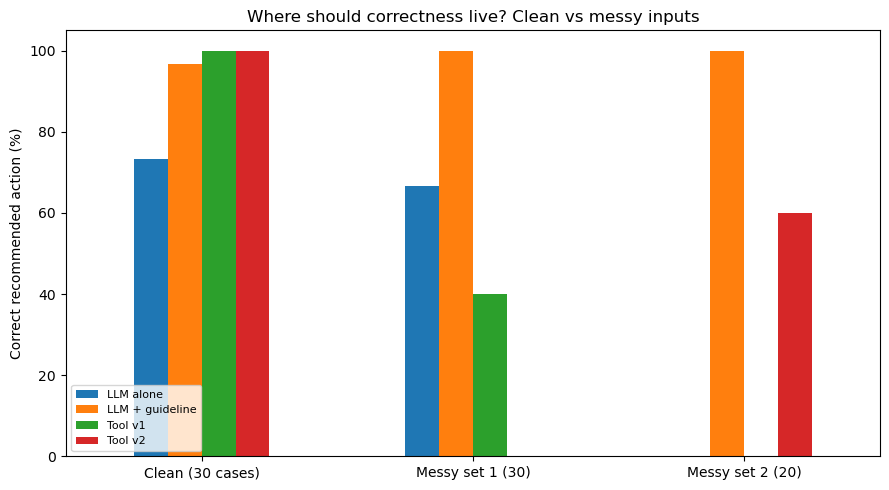

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

a = pd.read_csv("../data/results_llm_alone.csv")
b = pd.read_csv("../data/results_guideline.csv")
c1 = pd.read_csv("../data/results_tool.csv")
c2 = pd.read_csv("../data/results_tool_v2_clean.csv")
r1 = pd.read_csv("../data/results_robust.csv")
r2 = pd.read_csv("../data/results_robust2.csv")
nan = float("nan")

def rate(df, setup=None):
    if setup is not None:
        df = df[df["setup"] == setup]
        if df.empty:
            return nan
    return round(df["action_ok"].mean() * 100, 1)

table = pd.DataFrame({
    "LLM alone": [rate(a), rate(r1, "LLM alone"), nan],
    "LLM + guideline": [rate(b), rate(r1, "LLM + guideline"), rate(r2, "LLM + guideline")],
    "Tool v1": [rate(c1), rate(r1, "LLM + tool"), rate(r2, "Tool v1")],
    "Tool v2": [rate(c2), nan, rate(r2, "Tool v2")],
}, index=["Clean (30 cases)", "Messy set 1 (30)", "Messy set 2 (20)"])
print(table)

ax = table.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_ylabel("Correct recommended action (%)")
ax.set_ylim(0, 105)
ax.set_title("Where should correctness live? Clean vs messy inputs")
ax.legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("../data/figure_comparison.png", dpi=200)
plt.show()

                  LLM alone  LLM + guideline  Tool v1  Tool v2
Clean (30 cases)       73.3             96.7    100.0    100.0
Messy set 1 (30)       66.7            100.0     40.0      NaN
Messy set 2 (20)        NaN            100.0      0.0     60.0


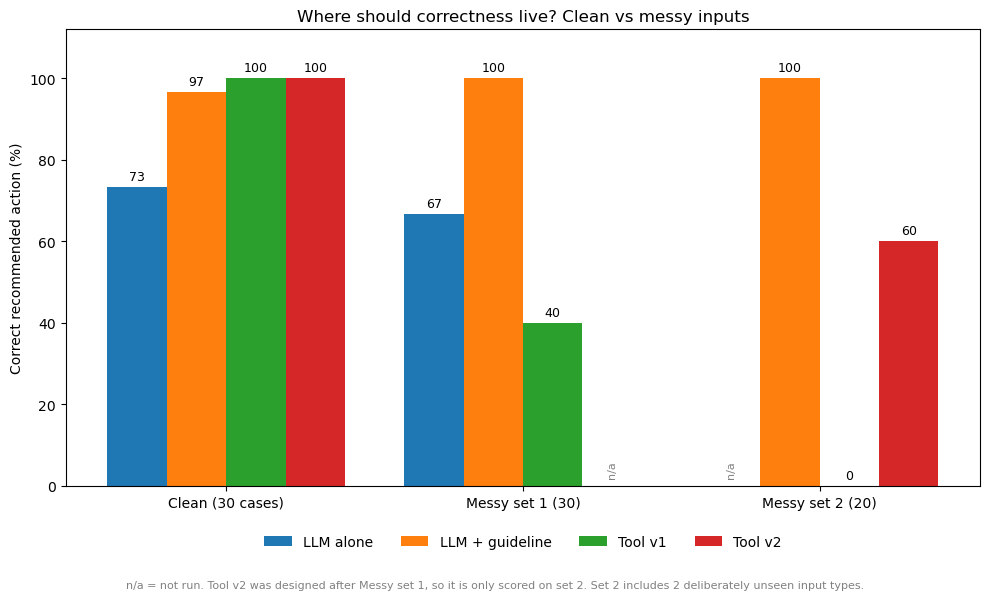

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1) Load the saved results
a = pd.read_csv("../data/results_llm_alone.csv")
b = pd.read_csv("../data/results_guideline.csv")
c1 = pd.read_csv("../data/results_tool.csv")
c2 = pd.read_csv("../data/results_tool_v2_clean.csv")
r1 = pd.read_csv("../data/results_robust.csv")
r2 = pd.read_csv("../data/results_robust2.csv")
nan = float("nan")

def rate(df, setup=None):
    if setup is not None:
        df = df[df["setup"] == setup]
        if df.empty:
            return nan
    return round(df["action_ok"].mean() * 100, 1)

# 2) Build the table (n/a = we did not run that combination)
table = pd.DataFrame({
    "LLM alone": [rate(a), rate(r1, "LLM alone"), nan],
    "LLM + guideline": [rate(b), rate(r1, "LLM + guideline"), rate(r2, "LLM + guideline")],
    "Tool v1": [rate(c1), rate(r1, "LLM + tool"), rate(r2, "Tool v1")],
    "Tool v2": [rate(c2), nan, rate(r2, "Tool v2")],
}, index=["Clean (30 cases)", "Messy set 1 (30)", "Messy set 2 (20)"])
print(table)

# 3) Draw the chart
groups = list(table.index)
setups = list(table.columns)
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
w = 0.2
x = np.arange(len(groups))

fig, ax = plt.subplots(figsize=(10, 6))
for i, s in enumerate(setups):
    for j, g in enumerate(groups):
        v = table.loc[g, s]
        xpos = x[j] + (i - 1.5) * w
        if pd.isna(v):
            ax.text(xpos, 2, "n/a", ha="center", va="bottom", fontsize=8,
                    rotation=90, color="gray")
        else:
            ax.bar(xpos, v, w, color=colors[i], label=s if j == 0 else None)
            ax.text(xpos, v + 1, f"{v:.0f}", ha="center", va="bottom", fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(groups)
ax.set_ylabel("Correct recommended action (%)")
ax.set_ylim(0, 112)
ax.set_title("Where should correctness live? Clean vs messy inputs")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=4, frameon=False)
fig.text(0.5, 0.01,
         "n/a = not run. Tool v2 was designed after Messy set 1, so it is only scored on set 2. "
         "Set 2 includes 2 deliberately unseen input types.",
         ha="center", fontsize=8, color="gray")
plt.tight_layout(rect=(0, 0.04, 1, 1))
plt.savefig("../data/figure_comparison.png", dpi=200)
plt.show()